# # 99 · All architectures side by side
# Collects the numbers every notebook saved to `data/results/` (run notebooks 01–13 first).
# All next-token models used the same data (char-level tiny-Shakespeare), context 64 and AdamW + one-cycle LR.
#
# **Read this table carefully:**
# * most models train for **1 200 steps**; the two slowest ones (Mamba: 500 steps, hybrid: 400 steps — their selective scan is a plain Python loop) got a **smaller budget**, see the `steps` column;
# * model sizes differ (0.2 M – 1.0 M parameters; the MoE and hybrid have many more *total* parameters than *active* ones);
# * one seed, tiny scale.
#
# So treat the numbers as intuition about each family, **not** as a leaderboard.

---

### At a glance

| | |
|---|---|
| **Family** | Comparison |
| **Representative models** | all notebooks |
| **Core idea** | Collect the results of every architecture in one table (with parameters and training steps). |
| **Compute / memory** | – |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 2 s on a laptop CPU |

### What you will learn

- Compare quality vs size for all next-token models
- Keep non-comparable objectives (MLM, seq2seq, diffusion) separate
- Learn to read a small-scale comparison critically

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import json
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from llmarch import DATA_DIR, setup_style
setup_style()
res = pd.DataFrame([json.loads(f.read_text()) for f in sorted((DATA_DIR / "results").glob("*.json"))]).set_index("name")
res.index.name = "notebook / model"
comparable = res[res.note.isna()] if "note" in res else res

# ## Next-token models (directly comparable)

,params_k,steps,val_loss,val_ppl
notebook / model,,,,
10 RWKV,313.1,1000,1.597,4.938
08 GRU,214.8,1200,1.648,5.195
04 LLaMA-style decoder (RMSNorm+RoPE+SwiGLU+GQA),311,1200,1.652,5.22
"07 MoE (8 experts top-2, Mixtral-style)","1,005",1200,1.655,5.232
09 Mamba (SSM),426.8,500,1.673,5.329
11 Hybrid Mamba+Attn+MoE (Jamba-style),900.3,400,1.737,5.679
08 LSTM,280.9,1200,1.771,5.877
01 GPT (decoder-only),354.2,1200,1.773,5.889
10 RetNet (retention),338.8,1000,2.222,9.224


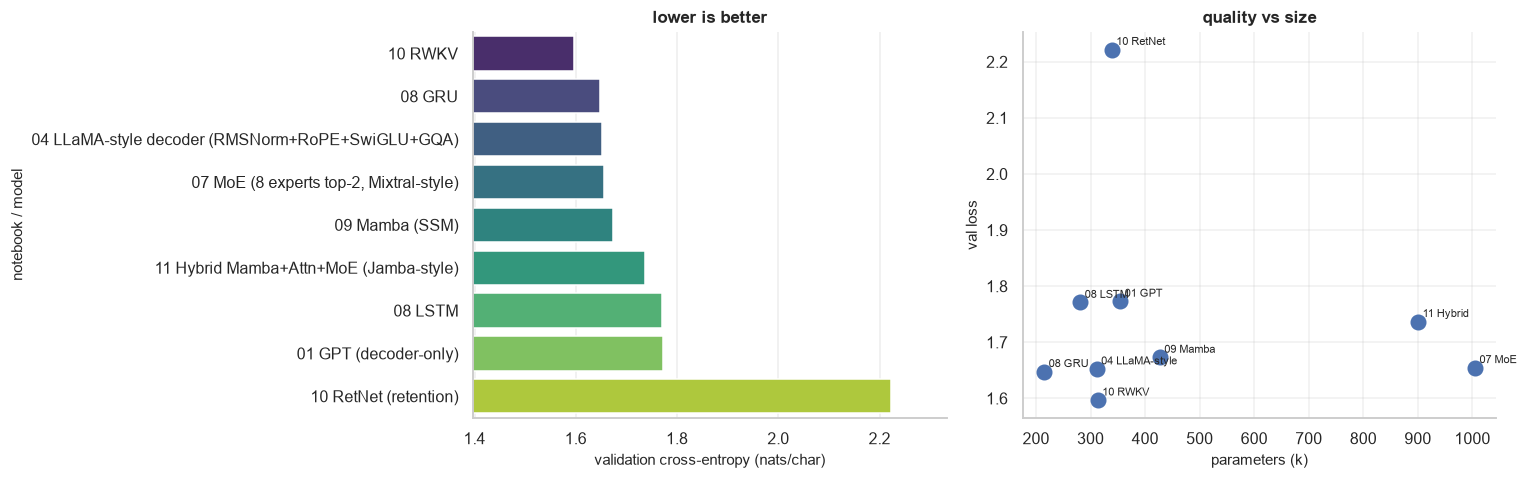

In [2]:
c = comparable.sort_values("val_loss"); c = c.assign(val_ppl=np.exp(c.val_loss.astype(float)), params_k=c.params / 1e3)
display(c[["params_k", "steps", "val_loss", "val_ppl"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(y=c.index, x=c.val_loss.astype(float), ax=ax[0], palette="viridis"); ax[0].set(xlabel="validation cross-entropy (nats/char)", title="lower is better"); ax[0].set_xlim(c.val_loss.astype(float).min() - .2)
ax[1].scatter(c.params_k, c.val_loss.astype(float), s=90)
for n, r in c.iterrows(): ax[1].annotate(n.split(" ")[0] + " " + n.split(" ")[1], (r.params_k, float(r.val_loss)), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set(xlabel="parameters (k)", ylabel="val loss", title="quality vs size"); ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()

# ## Everything else (different objectives — not comparable with the above)

In [3]:
res[res.note.notna()][["params", "val_loss", "note"]] if "note" in res else None

,params,val_loss,note
notebook / model,,,
"02 BERT (encoder-only, MLM loss)",360641,2.414,"masked-LM loss, not comparable to next-token loss"
03 Encoder-decoder (seq2seq reverse task),238493,0.0001866,different task
13 Masked diffusion LM (masked-token CE),795520,2.51,"masked-token CE, not next-token loss"


# ## Cheat-sheet: when does each family win?

In [4]:
pd.DataFrame([
 ["Decoder-only Transformer", "general LLMs, chat, code", "strongest quality/scaling, parallel training", "KV cache & O(T²) attention"],
 ["Encoder-only", "embeddings, classification, retrieval", "bidirectional context", "not generative"],
 ["Encoder-decoder", "translation, summarisation, speech", "clean input/output split; cross-attention", "more complex, less used for chat"],
 ["MoE", "scaling capacity cheaply", "more params at same FLOPs", "memory footprint, routing instability"],
 ["RNN / LSTM / GRU", "tiny streaming models", "constant memory", "sequential training, forgetting"],
 ["Mamba / SSM", "very long sequences, streaming", "linear time, constant state", "weaker exact recall"],
 ["Linear attn / RetNet / RWKV", "efficient inference with parallel training", "RNN inference, Transformer-like training", "recall limited by fixed state"],
 ["Hybrid (Jamba)", "long-context production LLMs", "mixes recall + efficiency", "engineering complexity"],
 ["ViT / VLM", "images, documents, multimodal", "reuses the Transformer for pixels", "needs lots of data"],
 ["Diffusion LM", "parallel decoding, infilling", "bidirectional, any-order generation", "multiple denoising steps, young ecosystem"],
], columns=["family", "typical use", "strength", "weakness"])

,family,typical use,strength,weakness
0,Decoder-only Transformer,"general LLMs, chat, code","strongest quality/scaling, parallel training",KV cache & O(T²) attention
1,Encoder-only,"embeddings, classification, retrieval",bidirectional context,not generative
2,Encoder-decoder,"translation, summarisation, speech",clean input/output split; cross-attention,"more complex, less used for chat"
3,MoE,scaling capacity cheaply,more params at same FLOPs,"memory footprint, routing instability"
4,RNN / LSTM / GRU,tiny streaming models,constant memory,"sequential training, forgetting"
5,Mamba / SSM,"very long sequences, streaming","linear time, constant state",weaker exact recall
6,Linear attn / RetNet / RWKV,efficient inference with parallel training,"RNN inference, Transformer-like training",recall limited by fixed state
7,Hybrid (Jamba),long-context production LLMs,mixes recall + efficiency,engineering complexity
8,ViT / VLM,"images, documents, multimodal",reuses the Transformer for pixels,needs lots of data
9,Diffusion LM,"parallel decoding, infilling","bidirectional, any-order generation","multiple denoising steps, young ecosystem"


---

## Key takeaways

- Recipe details (LLaMA-style vs GPT-2-style) matter as much as the architecture *family* at this scale.
- Recurrent / linear-time families (GRU, RWKV, Mamba) are competitive with attention on character-level text, but note the different training budgets in the `steps` column.
- Our simple RetNet implementation (no gating, no xPos) is clearly weaker – implementation details matter.
- Scale, data and optimisation change the picture: treat this as an intuition-builder, not a benchmark.

---
*← previous: `13_diffusion_language_model`*